# Avaliações de clientes Olist: o que explica a insatisfação?

**Pergunta de negócio:** quais fatores levam um cliente a dar nota 1 ou 2 para uma compra?

Este notebook faz a análise exploratória das cerca de 100 mil avaliações do e-commerce Olist, cruzando a nota com o
**atraso na entrega**, a **categoria do produto** e o **estado do cliente**. O notebook `02_classificacao_gemini.ipynb`
complementa a análise lendo o texto dos comentários negativos com IA generativa.

**Dados:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle, 2016–2018).
Coloque os arquivos `.csv` na pasta `dados/` antes de rodar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DADOS = "../dados"
IMG = "../img"

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Leitura dos dados

In [2]:
reviews = pd.read_csv(f"{DADOS}/olist_order_reviews_dataset.csv",
                      parse_dates=["review_creation_date", "review_answer_timestamp"])
orders = pd.read_csv(f"{DADOS}/olist_orders_dataset.csv",
                     parse_dates=["order_purchase_timestamp", "order_delivered_customer_date",
                                  "order_estimated_delivery_date"])
items = pd.read_csv(f"{DADOS}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{DADOS}/olist_products_dataset.csv")
customers = pd.read_csv(f"{DADOS}/olist_customers_dataset.csv")

for nome, df in [("reviews", reviews), ("orders", orders), ("items", items),
                 ("products", products), ("customers", customers)]:
    print(f"{nome:10} {df.shape[0]:>7,} linhas  {df.shape[1]:>2} colunas")

reviews     99,224 linhas   7 colunas
orders      99,441 linhas   8 colunas
items      112,650 linhas   7 colunas
products    32,951 linhas   9 colunas
customers   99,441 linhas   5 colunas


## 2. Preparação

- **Uma avaliação por pedido:** alguns pedidos têm mais de uma avaliação; fico com a última respondida.
- **Categoria do pedido:** a do primeiro item, já que a maioria dos pedidos tem um item só.
- **Atraso:** dias entre a data de entrega e a data prometida ao cliente (positivo = atrasou).
- **Avaliação negativa:** nota 1 ou 2.

In [3]:
duplicadas = reviews.order_id.duplicated().sum()
reviews = (reviews.sort_values("review_answer_timestamp")
           .drop_duplicates("order_id", keep="last")
           .drop_duplicates("review_id", keep="last"))
print(f"Avaliações duplicadas por pedido removidas: {duplicadas}")

categoria = (items.sort_values(["order_id", "order_item_id"])
             .drop_duplicates("order_id")
             .merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
             [["order_id", "product_category_name"]])

base = (reviews
        .merge(orders, on="order_id", how="left")
        .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
        .merge(categoria, on="order_id", how="left"))

base["negativa"] = base["review_score"] <= 2
base["entregue"] = base["order_status"].eq("delivered") & base["order_delivered_customer_date"].notna()
base["dias_atraso"] = np.where(
    base["entregue"],
    (base["order_delivered_customer_date"].dt.normalize()
     - base["order_estimated_delivery_date"].dt.normalize()).dt.days,
    np.nan)

def faixa_atraso(d):
    if pd.isna(d):
        return "Não entregue"
    if d <= 0:
        return "No prazo"
    if d <= 3:
        return "1 a 3 dias"
    if d <= 7:
        return "4 a 7 dias"
    if d <= 14:
        return "8 a 14 dias"
    return "15+ dias"

base["faixa_atraso"] = base["dias_atraso"].map(faixa_atraso)
base["tem_comentario"] = base["review_comment_message"].fillna("").str.strip().ne("")
print(f"Base analítica: {len(base):,} avaliações")

Avaliações duplicadas por pedido removidas: 551
Base analítica: 98,095 avaliações


## 3. Panorama das notas

In [4]:
dist = (base.review_score.value_counts(normalize=True).sort_index() * 100).round(1)
print(dist.to_string())
print()
print(f"Nota média: {base.review_score.mean():.2f}")
print(f"Avaliações negativas (nota 1 ou 2): {base.negativa.mean():.1%}")
print(f"Avaliações com comentário escrito: {base.tem_comentario.mean():.1%}")
print(f"Negativas com comentário escrito: {base[base.negativa].tem_comentario.mean():.1%}")

review_score
1   11.50
2    3.20
3    8.20
4   19.30
5   57.80

Nota média: 4.09
Avaliações negativas (nota 1 ou 2): 14.6%
Avaliações com comentário escrito: 41.3%
Negativas com comentário escrito: 74.8%


A maioria dos clientes está satisfeita (quase 58% dão nota 5), mas **cerca de 15% das avaliações são negativas**.
E três em cada quatro clientes insatisfeitos escrevem um comentário, uma fonte rica para entender o porquê.

In [5]:
# Estilo dos gráficos
plt.rcParams.update({
    "font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
TXT, TXT2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
AZUL, LARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
FONTE = "Fonte: Olist Brazilian E-Commerce Public Dataset (2016–2018). Análise: Matheus Cadoni."

def titulo(fig, t, s):
    h = fig.get_figheight()
    fig.text(0.04, 1 - 0.3 / h, t, fontsize=17, fontweight="bold", color=TXT, va="top")
    fig.text(0.04, 1 - 0.68 / h, s, fontsize=12, color=TXT2, va="top")

def fonte(fig):
    fig.text(0.04, 0.025, FONTE, fontsize=9.5, color="#8a8984")

## 4. O atraso na entrega derruba a nota?

In [6]:
ordem = ["No prazo", "1 a 3 dias", "4 a 7 dias", "8 a 14 dias", "15+ dias", "Não entregue"]
por_faixa = (base.groupby("faixa_atraso")
             .agg(pedidos=("review_id", "size"), nota_media=("review_score", "mean"),
                  pct_negativas=("negativa", "mean"))
             .reindex(ordem))
por_faixa["pct_negativas"] = (por_faixa["pct_negativas"] * 100).round(1)
entregues = base[base.entregue]
print(f"Pedidos entregues com atraso: {(entregues.dias_atraso > 0).mean():.1%}")
por_faixa

Pedidos entregues com atraso: 6.7%


,pedidos,nota_media,pct_negativas
faixa_atraso,,,
No prazo,88943,4.29,9.20
1 a 3 dias,1846,3.29,32.10
4 a 7 dias,1737,2.11,67.50
8 a 14 dias,1441,1.67,80.20
15+ dias,1326,1.72,78.40
Não entregue,2802,1.74,78.30


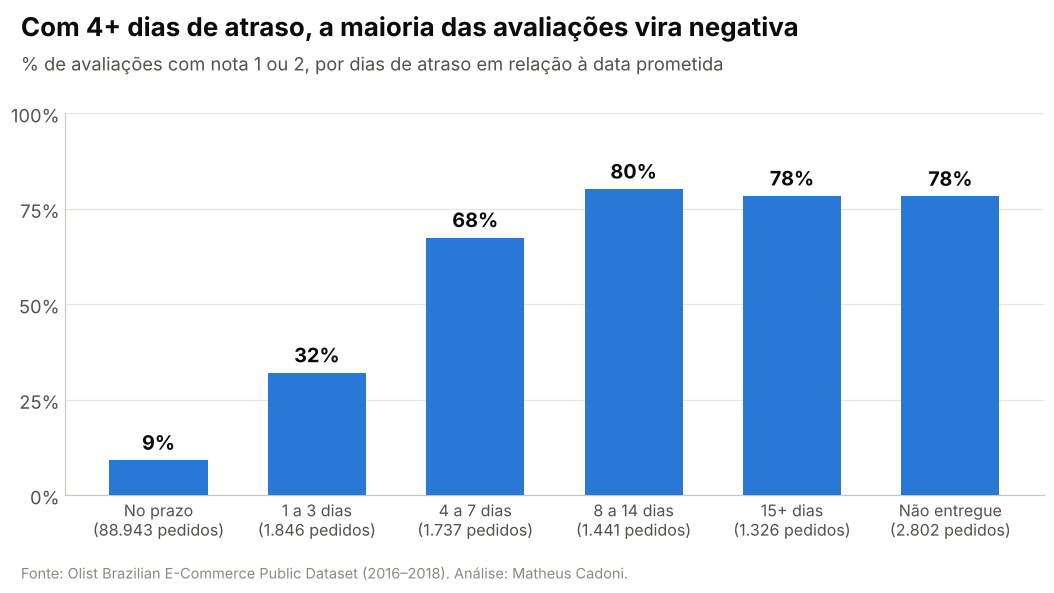

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(left=0.08, right=0.97, top=0.78, bottom=0.16)
xs = range(len(ordem))
ax.bar(xs, por_faixa["pct_negativas"], width=0.62, color=AZUL, zorder=3)
for x, v in zip(xs, por_faixa["pct_negativas"]):
    ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", va="bottom", fontsize=13, fontweight="bold", color=TXT)
rotulos = [f"{o}\n({n:,} pedidos)".replace(",", ".") for o, n in zip(ordem, por_faixa["pedidos"])]
ax.set_xticks(list(xs), rotulos, fontsize=10.5)
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.yaxis.grid(True, color=GRID, zorder=0)
ax.tick_params(length=0)
titulo(fig, "Com 4+ dias de atraso, a maioria das avaliações vira negativa",
       "% de avaliações com nota 1 ou 2, por dias de atraso em relação à data prometida")
fonte(fig)
fig.savefig(f"{IMG}/1_atraso_x_negativas.png", dpi=160)
plt.show()

**O atraso é decisivo.** Pedidos no prazo têm 9% de avaliações negativas. Com 1 a 3 dias de atraso, a taxa sobe para
32%; a partir de 4 dias, **mais de dois terços** dos clientes dão nota 1 ou 2. Um pedido não entregue fica no
mesmo patamar de um atraso longo.

## 5. Mas o atraso explica toda a insatisfação?

In [8]:
negativas = base[base.negativa]
origem = pd.Series({
    "Entregue no prazo": (negativas.dias_atraso <= 0).mean() * 100,
    "Entregue com atraso": (negativas.dias_atraso > 0).mean() * 100,
    "Não entregue": (~negativas.entregue).mean() * 100,
}).round(1)
print(f"Total de avaliações negativas: {len(negativas):,}")
origem

Total de avaliações negativas: 14,350


Entregue no prazo     57.10
Entregue com atraso   27.60
Não entregue          15.30
dtype: float64

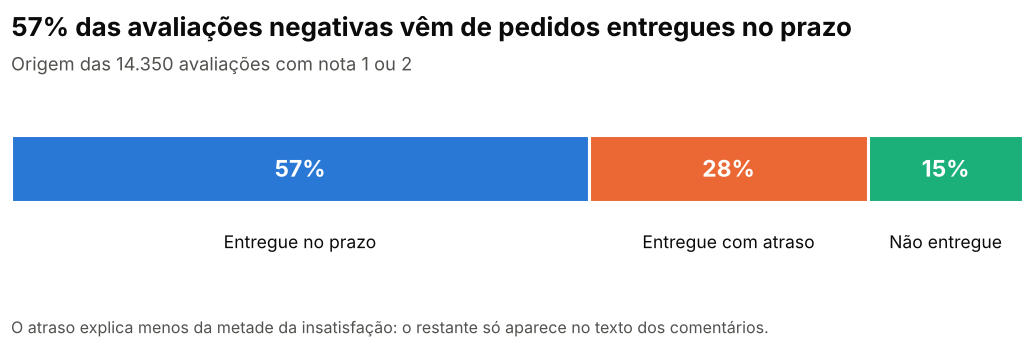

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.4))
fig.subplots_adjust(left=0.04, right=0.96, top=0.62, bottom=0.2)
x0 = 0
for (nome, v), cor in zip(origem.items(), [AZUL, LARANJA, AQUA]):
    ax.barh(0, v, left=x0, height=0.55, color=cor, edgecolor="#ffffff", linewidth=2)
    ax.text(x0 + v / 2, 0, f"{v:.0f}%", ha="center", va="center", fontsize=15, fontweight="bold", color="#ffffff")
    ax.text(x0 + v / 2, -0.52, nome, ha="center", va="top", fontsize=11.5, color=TXT)
    x0 += v
ax.set_xlim(0, 100)
ax.set_ylim(-0.9, 0.4)
ax.axis("off")
titulo(fig, "57% das avaliações negativas vêm de pedidos entregues no prazo",
       f"Origem das {len(negativas):,} avaliações com nota 1 ou 2".replace(",", "."))
fig.text(0.04, 0.05, "O atraso explica menos da metade da insatisfação: o restante só aparece no texto dos comentários.",
         fontsize=10.5, color=TXT2)
fig.savefig(f"{IMG}/2_origem_negativas.png", dpi=160)
plt.show()

**Este é o achado central.** Apesar do peso do atraso, **a maior parte das avaliações negativas (57%) vem de pedidos
entregues no prazo**. Ou seja, a logística explica menos da metade da insatisfação. Para entender o resto, é preciso
ler o que os clientes escreveram: é o que o notebook `02_classificacao_gemini.ipynb` faz com IA generativa.

## 6. Quais categorias geram insatisfação mesmo com entrega no prazo?

In [10]:
NOMES = {"moveis_escritorio": "Móveis de escritório", "cama_mesa_banho": "Cama, mesa e banho",
         "moveis_decoracao": "Móveis e decoração", "informatica_acessorios": "Informática e acessórios",
         "telefonia": "Telefonia", "relogios_presentes": "Relógios e presentes", "eletronicos": "Eletrônicos",
         "automotivo": "Automotivo", "bebes": "Bebês", "utilidades_domesticas": "Utilidades domésticas",
         "ferramentas_jardim": "Ferramentas e jardim", "perfumaria": "Perfumaria", "pet_shop": "Pet shop",
         "cool_stuff": "Cool stuff", "brinquedos": "Brinquedos", "esporte_lazer": "Esporte e lazer",
         "beleza_saude": "Beleza e saúde", "fashion_bolsas_e_acessorios": "Bolsas e acessórios",
         "papelaria": "Papelaria"}

no_prazo = base[base.entregue & (base.dias_atraso <= 0)]
por_cat = (no_prazo.groupby("product_category_name")
           .agg(avaliacoes=("review_id", "size"), pct_negativas=("negativa", "mean")))
por_cat = por_cat[por_cat.avaliacoes >= 1000].sort_values("pct_negativas")
por_cat["pct_negativas"] = por_cat["pct_negativas"] * 100
por_cat.index = [NOMES.get(i, i) for i in por_cat.index]
media_no_prazo = no_prazo.negativa.mean() * 100
por_cat.sort_values("pct_negativas", ascending=False).round(1)

,avaliacoes,pct_negativas
Móveis de escritório,1132,18.30
"Cama, mesa e banho",8321,11.80
Móveis e decoração,5672,11.40
Informática e acessórios,6014,11.20
Telefonia,3761,10.80
Relógios e presentes,5026,9.60
Eletrônicos,2295,9.20
Bebês,2511,9.10
Automotivo,3489,9.10
Utilidades domésticas,5340,8.70


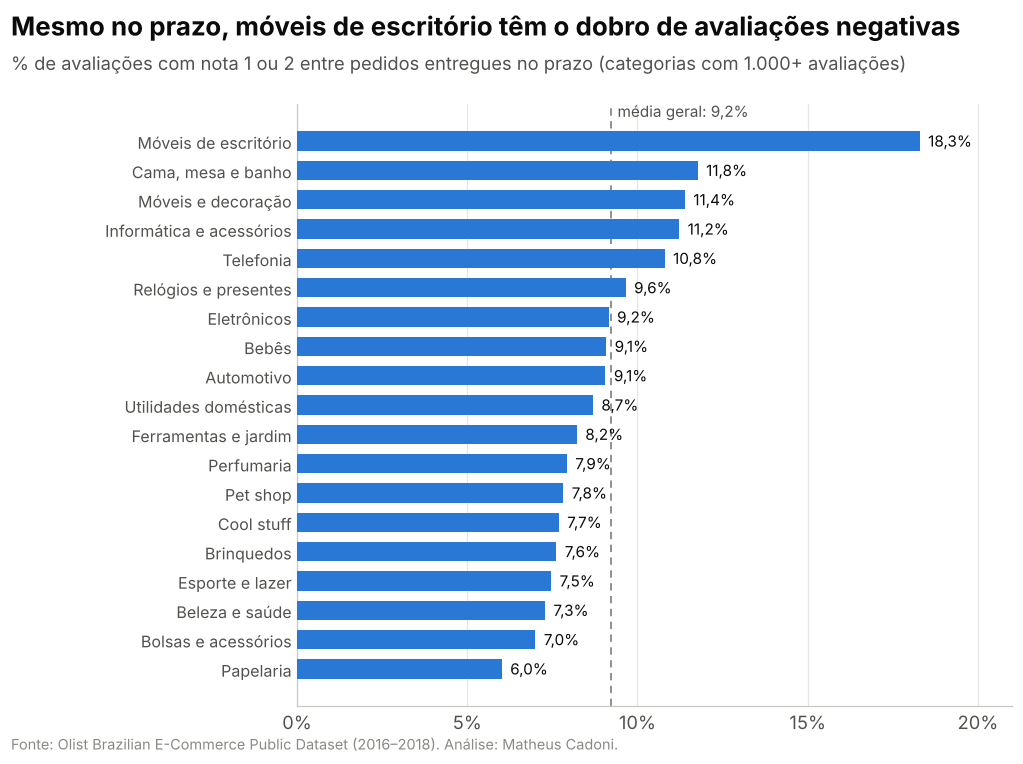

In [11]:
fig, ax = plt.subplots(figsize=(10, 7.2))
fig.subplots_adjust(left=0.30, right=0.95, top=0.84, bottom=0.08)
ys = range(len(por_cat))
ax.barh(list(ys), por_cat["pct_negativas"], height=0.66, color=AZUL, zorder=3)
for y, v in zip(ys, por_cat["pct_negativas"]):
    ax.text(v + 0.25, y, f"{v:.1f}%".replace(".", ","), va="center", fontsize=10, color=TXT)
ax.set_yticks(list(ys), por_cat.index, fontsize=10.5)
ax.axvline(media_no_prazo, color="#8a8984", linestyle=(0, (4, 3)), linewidth=1.2, zorder=2)
ax.text(media_no_prazo + 0.2, len(por_cat) - 0.3, f"média geral: {media_no_prazo:.1f}%".replace(".", ","),
        fontsize=10, color=TXT2, va="bottom")
ax.set_xlim(0, 21)
ax.set_xticks([0, 5, 10, 15, 20], ["0%", "5%", "10%", "15%", "20%"])
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.tick_params(length=0)
titulo(fig, "Mesmo no prazo, móveis de escritório têm o dobro de avaliações negativas",
       "% de avaliações com nota 1 ou 2 entre pedidos entregues no prazo (categorias com 1.000+ avaliações)")
fonte(fig)
fig.savefig(f"{IMG}/3_categorias_no_prazo.png", dpi=160)
plt.show()

Isolando só os pedidos entregues no prazo, **móveis de escritório** se destacam com 18% de avaliações negativas,
o dobro da média. Móveis, cama/mesa/banho, informática e telefonia também ficam acima da média: categorias em que
montagem, qualidade do material e expectativa sobre o produto tendem a pesar mais.

## 7. Estados: atraso e insatisfação andam juntos

In [12]:
por_uf = (base[base.entregue].groupby("customer_state")
          .agg(avaliacoes=("review_id", "size"),
               pct_atraso=("dias_atraso", lambda s: (s > 0).mean() * 100)))
por_uf["pct_negativas"] = base.groupby("customer_state").negativa.mean() * 100
por_uf = por_uf[por_uf.avaliacoes >= 200]
correlacao = por_uf[["pct_atraso", "pct_negativas"]].corr().iloc[0, 1]
print(f"Correlação entre % de atraso e % de negativas por estado: {correlacao:.2f}")
por_uf.sort_values("pct_atraso", ascending=False).round(1).head(10)

Correlação entre % de atraso e % de negativas por estado: 0.88


,avaliacoes,pct_atraso,pct_negativas
customer_state,,,
AL,393,20.60,23.50
MA,706,17.30,22.00
SE,331,15.10,22.00
CE,1271,13.70,19.60
PI,469,13.60,18.40
RJ,12131,11.90,20.60
BA,3212,11.90,18.90
PA,924,10.60,19.50
ES,1962,10.40,15.00


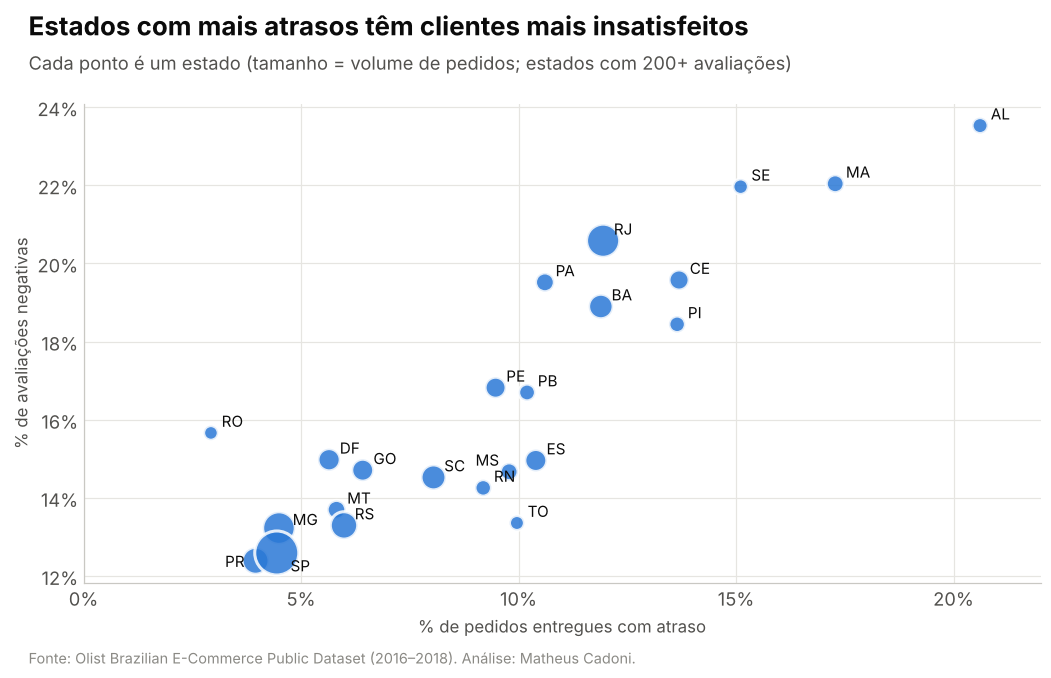

In [13]:
fig, ax = plt.subplots(figsize=(10, 6.4))
fig.subplots_adjust(left=0.09, right=0.96, top=0.82, bottom=0.14)
ax.scatter(por_uf.pct_atraso, por_uf.pct_negativas, s=(por_uf.avaliacoes ** 0.5) * 4 + 30,
           color=AZUL, alpha=0.85, edgecolor="#ffffff", linewidth=2, zorder=3)
deslocamento = {"PR": (-20, -4), "SP": (9, -12), "MG": (9, 2), "MS": (-22, 4)}
for uf, r in por_uf.iterrows():
    ax.annotate(uf, (r.pct_atraso, r.pct_negativas), xytext=deslocamento.get(uf, (7, 4)),
                textcoords="offset points", fontsize=10, color=TXT)
ax.set_xlabel("% de pedidos entregues com atraso", fontsize=11)
ax.set_ylabel("% de avaliações negativas", fontsize=11)
ax.grid(True, color=GRID, zorder=0)
ax.tick_params(length=0)
ax.set_xticks([0, 5, 10, 15, 20])
ax.set_xlim(0, 22)
ax.xaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
ax.yaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
titulo(fig, "Estados com mais atrasos têm clientes mais insatisfeitos",
       "Cada ponto é um estado (tamanho = volume de pedidos; estados com 200+ avaliações)")
fonte(fig)
fig.savefig(f"{IMG}/4_estados.png", dpi=160)
plt.show()

Por estado, a relação é forte (correlação de 0,88): **Alagoas, Maranhão e Sergipe** têm as maiores taxas de
atraso e também as maiores de insatisfação, enquanto **SP, PR e MG**, mais próximos dos vendedores, ficam no canto
oposto. O **Rio de Janeiro** chama atenção por combinar alto volume com atraso e insatisfação acima da média.

## 8. Conclusões

1. **O atraso é o maior gatilho de insatisfação:** com 4 ou mais dias de atraso, cerca de 70% a 80% das avaliações
   são negativas, contra 9% nos pedidos no prazo.
2. **Mas ele não explica tudo:** 57% das avaliações negativas vêm de pedidos entregues no prazo.
3. **Categorias como móveis de escritório** concentram insatisfação mesmo sem atraso, o que aponta para problemas de
   produto, montagem ou expectativa.
4. **A geografia importa:** estados do Nordeste e o Rio de Janeiro combinam mais atraso e mais avaliações negativas.

**Próximo passo:** classificar os comentários negativos com IA generativa para descobrir o que explica a
insatisfação dos pedidos entregues no prazo (`02_classificacao_gemini.ipynb`).